# Introduction


## Environment Setup
1. create new Neo4j instance
2. install APOC / Graph Data Science plugins

3. change config/neo4j.conf:
* server.memory.heap.initial_size=2g
* server.memory.heap.max_size=4g
* dbms.memory.transaction.total.max=4g (beware it's commented by default)
* create apoc.conf file with apoc.import.file.enabled=true

## Import Datasets
For each EKG to be imported, execute the following:
copy graphml file to import folder
<<link to source material?>>

import graphml file with
CALL apoc.import.graphml("filename.graphml", {
  batchSize: 500,
  readLabels: true,
  storeNodeIds: true
})


pip install jupyterlab neo4j pandas ipython-neo4j pyvis

# Imports / helper functions
Change URI / AUTH here (currently placeholders)

In [ ]:
from neo4j import GraphDatabase
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "password")

# Initialize driver
driver = GraphDatabase.driver(URI, auth=AUTH)

def run_cypher(query: str, parameters: dict = None, database: str = "neo4j", as_dataframe: bool = True):
    """
    Executes a Cypher query against Neo4j.
    
    :param query: Cypher query string
    :param parameters: Optional dictionary of query parameters
    :param database: Target database name (default: "neo4j")
    :param as_dataframe: If True, returns a pandas DataFrame; otherwise returns raw records
    """
    records, summary, keys = driver.execute_query(
        query,
        parameters_=parameters,
        database_=database,
    )
    
    if as_dataframe:
        return pd.DataFrame([r.values() for r in records], columns=keys)
    return [r.data() for r in records]

# Algorithm 1 & Algorithm 2
Functions for Algorithm 1 (FindBottleneckActivities) and Algorithm 2 (FindBottleneckObjects)

In [ ]:
def find_bottleneck_activities(coarse_type: str, fine_type: str, cutoff_date: str, database: str = "neo4j") -> pd.DataFrame:
    """
    For each Activity, finds activities where multiple 'fine' objects belonging to the
    same 'coarse' object corrolated to that activity, and computes how spread out
    (in seconds) their (last) occurrences were.

    :param coarse_type: EntityType of the grouping entity (e.g. "PO")
    :param fine_type: EntityType of the sub-entity being compared within each group (e.g. "POItem")
    :param cutoff_date: ISO-8601 datetime string; only events at or after this time are considered
                         (e.g. "2017-01-01T00:00:00+01:00")
    :param database: Target Neo4j database name
    :return: DataFrame with one row per activity, ranked by total spread descending
    """
    query = """
    MATCH (coarse:Entity {EntityType: $coarseType})<-[:CORR]-(:Event)-[:CORR]->(fine:Entity {EntityType: $fineType})
    WITH DISTINCT coarse, fine
    MATCH (fine)<-[:CORR]-(e:Event)
    WHERE datetime(e.timestamp) >= datetime($cutoffDate)
    WITH coarse, fine, e.Activity AS activity, max(datetime(e.timestamp)) AS fineActivityTime
    WITH coarse, activity, collect(fineActivityTime) AS times
    WHERE size(times) > 1
    WITH coarse, activity,
         coll.min(times) AS firstTime,
         coll.max(times) AS lastTime
    WITH activity, duration.inSeconds(firstTime, lastTime).seconds AS spreadSeconds
    RETURN
      activity,
      count(*)                           AS numCoarseAffected,
      sum(spreadSeconds)                 AS totalSpreadSeconds,
      avg(spreadSeconds)                 AS meanSpreadSeconds,
      percentileCont(spreadSeconds, 0.5) AS medianSpreadSeconds,
      max(spreadSeconds)                 AS worstCaseSpreadSeconds
    ORDER BY medianSpreadSeconds DESC
    """

    parameters = {
        "coarseType": coarse_type,
        "fineType": fine_type,
        "cutoffDate": cutoff_date,
    }

    return run_cypher(query, parameters=parameters, database=database)


def find_bottleneck_objects(coarse_type: str, fine_type: str, activity: str, cutoff_date: str, database: str = "neo4j") -> pd.DataFrame:
    """
    For each 'coarse' object with multiple 'fine' sub-object, finds each sub-object's
    first occurrence of the given Activity, and computes how spread out (in seconds)
    those first-occurrence times were across sibling sub-objects.

    :param coarse_type: EntityType of the grouping object (e.g. "PO")
    :param fine_type: EntityType of the sub-object being compared within each group (e.g. "POItem")
    :param activity: Activity name whose first occurrence per fine entity is measured (e.g. "Record Goods Receipt")
    :param cutoff_date: ISO-8601 datetime string; only events at or after this time are considered
                         (e.g. "2017-01-01T00:00:00+01:00")
    :param database: Target Neo4j database name
    :return: DataFrame with one row per coarse entity, ranked by spread descending
    """
    query = """
    // Step 1: find sibling fine entities under the same coarse entity
    MATCH (coarse:Entity {EntityType: $coarseType})<-[:CORR]-(:Event)-[:CORR]->(fine:Entity {EntityType: $fineType})
    WITH DISTINCT coarse, fine
    // Step 2: for each fine entity, find its (first) Activity timestamp at/after the cutoff
    MATCH (fine)<-[:CORR]-(ev:Event {Activity: $activity})
    WHERE datetime(ev.timestamp) >= datetime($cutoffDate)
    WITH coarse, fine, min(datetime(ev.timestamp)) AS fineActivityTime
    // Step 3: aggregate per coarse entity - collect list AND compute min/max in the same WITH
    WITH coarse,
         collect(fineActivityTime) AS activityTimes,
         min(fineActivityTime) AS firstFineTime,
         max(fineActivityTime) AS lastFineTime
    WHERE size(activityTimes) > 1
    RETURN
      coarse.ID AS coarseId,
      size(activityTimes) AS numFine,
      firstFineTime,
      lastFineTime,
      duration.inSeconds(firstFineTime, lastFineTime).seconds AS spreadSeconds
    ORDER BY spreadSeconds DESC
    """

    parameters = {
        "coarseType": coarse_type,
        "fineType": fine_type,
        "activity": activity,
        "cutoffDate": cutoff_date,
    }

    return run_cypher(query, parameters=parameters, database=database)

# Execution of Algorithm 1 FindBottleneckActivities for BPIC 2019

## Finding bottlenecks for all possible object type pairs

In [ ]:
import itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

ENTITY_TYPES = ["PO", "POItem", "Vendor"] # All but "Resource"
CUTOFF = "2017-01-01T00:00+01:00"
METRIC = "medianSpreadSeconds"
TOP_N  = 20          # activities to show
UNIT   = 3600.0      # seconds -> hours

# --- 1. all ordered pairs ---------------------------------------------------
frames = []
for coarse, fine in itertools.permutations(ENTITY_TYPES, 2):
    try:
        d = find_bottleneck_activities(coarse_type=coarse, fine_type=fine, cutoff_date=CUTOFF)
    except Exception as exc:
        print(f"{coarse} -> {fine}: FAILED ({exc})"); continue
    print(f"{coarse} -> {fine}: {0 if d is None else len(d)} activities")
    if d is None or d.empty: continue
    d = d.copy(); d["coarseType"], d["fineType"] = coarse, fine
    frames.append(d)

res = pd.concat(frames, ignore_index=True)

# --- 2. 3D heatmap ----------------------------------------------------------
res["value"] = res[METRIC].astype(float) / UNIT
rank = res.groupby("activity")["value"].max().sort_values(ascending=False).head(TOP_N)
p = res[res["activity"].isin(rank.index)]

xs, ys, zs = sorted(p.coarseType.unique()), sorted(p.fineType.unique()), list(rank.index[::-1])
x = p.coarseType.map({t: i for i, t in enumerate(xs)}).to_numpy()
y = p.fineType.map({t: i for i, t in enumerate(ys)}).to_numpy()
z = p.activity.map({a: i for i, a in enumerate(zs)}).to_numpy()

c = p["value"].to_numpy()
vmin = c[c > 0].min()
c = np.clip(c, vmin, None)
w = np.sqrt(p["numCoarseAffected"].to_numpy(float))
s = 30 + 290 * (w - w.min()) / (float(np.ptp(w)) or 1.0)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection="3d")
img = ax.scatter(x, y, z, c=c, s=s, cmap="viridis", norm=LogNorm(vmin=vmin, vmax=c.max()),
                 marker="s", edgecolors="black", linewidths=0.3, depthshade=False)

ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs, rotation=25, ha="right", fontsize=9)
ax.set_yticks(range(len(ys))); ax.set_yticklabels(ys, rotation=-25, ha="left", fontsize=9)
ax.set_zticks(range(len(zs))); ax.set_zticklabels(zs, fontsize=7)
ax.set_xlabel("Coarse EntityType", labelpad=18)
ax.set_ylabel("Fine EntityType", labelpad=18)
ax.set_zlabel("Activity", labelpad=48)
ax.set_title(f"Sibling spread per (coarse, fine, activity) — {METRIC}")
ax.view_init(elev=18, azim=-62)
fig.colorbar(img, ax=ax, shrink=0.65, pad=0.12).set_label(f"{METRIC} [hours, log scale]")
plt.show()

PO -> POItem: 39 activities


## Slicing the cube

In [ ]:
df = find_bottleneck_activities(coarse_type = 'PO', fine_type = 'POItem', cutoff_date = '2017-01-01T00:00+01:00')

In [ ]:
# Create BottleneckScore column
df["BottleneckScore"] = 100 * (df["numCoarseAffected"] / df["numCoarseAffected"].max())**0.5 \
                            * (np.log1p(df["medianSpreadSeconds"]) / np.log1p(df["medianSpreadSeconds"]).max())**0.5

In [ ]:
df.head(20)

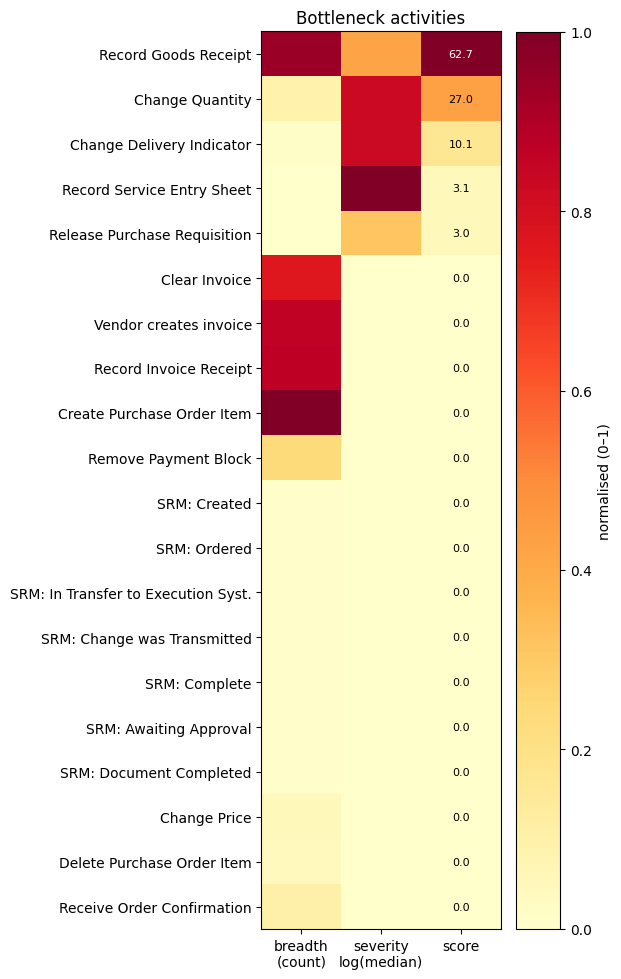

In [13]:
top = df.sort_values("BottleneckScore", ascending=False).head(20)
cols = ["numCoarseAffected", "medianSpreadSeconds", "BottleneckScore"]

M = top[cols].astype(float).to_numpy()
M[:, 1] = np.log1p(M[:, 1])                       # damp the duration axis
M = M / np.where(M.max(axis=0) == 0, 1, M.max(axis=0))

fig, ax = plt.subplots(figsize=(6, 0.42 * len(top) + 1.5))
im = ax.imshow(M, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(["breadth\n(count)", "severity\nlog(median)", "score"])
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["activity"])

for i, s in enumerate(top["BottleneckScore"]):
    ax.text(2, i, f"{s:.1f}", ha="center", va="center",
            color="white" if M[i, 2] > 0.55 else "black", fontsize=8)

fig.colorbar(im, ax=ax, label="normalised (0–1)")
ax.set_title("Bottleneck activities")
fig.tight_layout()
plt.show()

# Execution of Algorithm 2 FindBottleneckObjects for BPIC 2019

In [6]:
df2 = find_bottleneck_objects(coarse_type = 'PO', fine_type = 'POItem', activity = "Record Goods Receipt", cutoff_date = '2017-01-01T00:00+01:00')

In [7]:
df2.head(20)

,coarseId,numFine,firstFineTime,lastFineTime,spreadSeconds
0,4507007862,12,2018-02-08T16:26:00.000000000+01:00,2019-01-17T16:10:00.000000000+01:00,29634240
1,4507000430,3,2018-01-02T15:25:00.000000000+01:00,2018-11-27T08:56:00.000000000+01:00,28402260
2,4507012472,12,2018-02-26T16:03:00.000000000+01:00,2019-01-04T10:13:00.000000000+01:00,26935800
3,4507003965,25,2018-01-22T12:48:00.000000000+01:00,2018-10-30T11:37:00.000000000+01:00,24274140
4,4507007945,10,2018-02-06T12:54:00.000000000+01:00,2018-11-08T16:07:00.000000000+01:00,23771580
5,4507002187,9,2018-01-11T14:37:00.000000000+01:00,2018-09-27T17:43:00.000000000+01:00,22388760
6,4507019873,14,2018-04-06T19:23:00.000000000+01:00,2018-12-19T09:50:00.000000000+01:00,22170420
7,4507004992,2,2018-01-31T19:08:00.000000000+01:00,2018-10-15T07:36:00.000000000+01:00,22163280
8,4507001411,4,2018-01-10T12:06:00.000000000+01:00,2018-09-17T14:11:00.000000000+01:00,21607500
9,4507000907,2,2018-01-11T11:56:00.000000000+01:00,2018-09-17T14:11:00.000000000+01:00,21521700


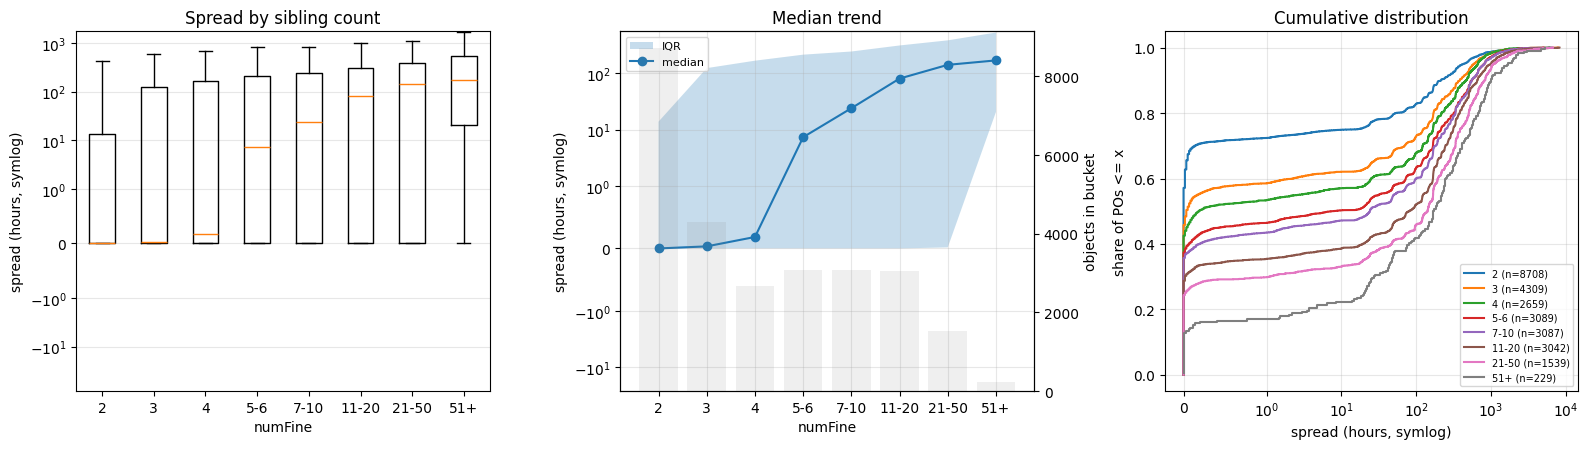

,nObjects,zeroShare,p25,median,p75,p95,max
bucket,,,,,,,
2,8708,0.571429,0.000000,0.000000,13.854167,427.957500,6156.466667
3,4309,0.457647,0.000000,0.033333,123.550000,583.160000,7889.516667
4,2659,0.425348,0.000000,0.183333,167.433333,669.698333,6002.083333
5-6,3089,0.373907,0.000000,7.333333,214.216667,810.096667,5041.066667
7-10,3087,0.357305,0.000000,23.966667,243.691667,813.700000,6603.216667
11-20,3042,0.287311,0.000000,80.575000,312.087500,988.535000,8231.733333
21-50,1539,0.243665,0.016667,141.300000,384.666667,1075.366667,6742.816667
51+,229,0.126638,20.600000,169.400000,529.583333,1664.350000,5191.000000


In [12]:
UNIT, DIV = "hours", 3600.0
BINS   = [1, 2, 3, 4, 6, 10, 20, 50, np.inf]
LABELS = ["2", "3", "4", "5-6", "7-10", "11-20", "21-50", "51+"]

d = df2.assign(
    bucket=pd.cut(df2["numFine"], bins=BINS, labels=LABELS, right=True),
    spread=df2["spreadSeconds"] / DIV,
).dropna(subset=["bucket"])

buckets = [b for b in LABELS if (d["bucket"] == b).any()]
groups  = [d.loc[d["bucket"] == b, "spread"].to_numpy() for b in buckets]
x = np.arange(len(buckets))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# box plot per bucket
ax = axes[0]
ax.boxplot(groups, showfliers=False, whis=(5, 95))
ax.set_xticks(np.arange(1, len(buckets) + 1)); ax.set_xticklabels(buckets)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("numFine"); ax.set_ylabel(f"spread ({UNIT}, symlog)")
ax.set_title("Spread by sibling count"); ax.grid(axis="y", alpha=0.3)

# median + IQR band, with bucket sizes behind it
ax = axes[1]
med = [np.median(g) for g in groups]
q1  = [np.percentile(g, 25) for g in groups]
q3  = [np.percentile(g, 75) for g in groups]
ax.fill_between(x, q1, q3, alpha=0.25, label="IQR")
ax.plot(x, med, marker="o", label="median")
ax.set_xticks(x); ax.set_xticklabels(buckets)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("numFine"); ax.set_ylabel(f"spread ({UNIT}, symlog)")
ax.set_title("Median trend"); ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
cnt = ax.twinx()
cnt.bar(x, [len(g) for g in groups], alpha=0.12, color="grey", zorder=0)
cnt.set_ylabel("objects in bucket")

# ECDF per bucket
ax = axes[2]
for b, g in zip(buckets, groups):
    xs = np.sort(g)
    ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=f"{b} (n={len(xs)})")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel(f"spread ({UNIT}, symlog)"); ax.set_ylabel("share of POs <= x")
ax.set_title("Cumulative distribution"); ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# summary table
g = d.groupby("bucket", observed=True)["spread"]
pd.DataFrame({
    "nObjects":  g.size(),
    "zeroShare": g.apply(lambda s: (s == 0).mean()),
    "p25": g.quantile(0.25), "median": g.median(),
    "p75": g.quantile(0.75), "p95": g.quantile(0.95), "max": g.max(),
})